# Iovance: a data-first statistical roadmap

**Companion notebook · 31 October 2026**

This notebook reproduces the numbers in the [web article](https://tkinley.github.io/kinley-website/statistics/iovance-data-first.html)
from the [primary release](https://ir.iovance.com/news-releases/news-release-details/iovance-reports-updated-iov-lun-202-results-and-adds-precision). Source release: 29 October 2026;
data cutoff: 14 October 2026. This is a dated educational case study using aggregate counts,
not a live clinical update or a patient-level reanalysis.

**Order:** observed data → selection and assumptions → sampling uncertainty → conditional prediction → validation.

Run all cells in order with Python 3.9+ and Matplotlib. The calculations use only Python's standard library.
If needed, install Matplotlib in your notebook environment with `%pip install matplotlib`.

## 1. Understand what was observed

The table contains overlapping populations. The KRAS wild-type + HER2 wild-type and enriched
populations are nested within the KRAS wild-type population. Do not add the rows.
The two KRAS groups account for 65 of 69 patients; four were KRAS-unassessed.
The reported overall 17 responses include two unconfirmed partial responses, one in each KRAS group.
The enriched subgroup includes one unconfirmed response; 12/22 is examined later as a confirmed-response sensitivity.
No individual patient records or full subgroup search history are available here.

In [1]:
from math import sqrt, comb, lgamma, exp, isclose
from statistics import NormalDist, mean
from random import Random
import os
from pathlib import Path
import matplotlib.pyplot as plt

populations = [
    ('Broader population', 17, 69),
    ('KRAS wild-type', 13, 30),
    ('KRAS-mutant', 4, 35),
    ('KRAS WT + HER2 WT', 13, 25),
    ('Enriched subgroup', 13, 22),
]
for label, x, n in populations:
    print(f'{label:24s} {x:2d}/{n:2d} = {x/n:6.1%}')

Broader population       17/69 =  24.6%
KRAS wild-type           13/30 =  43.3%
KRAS-mutant               4/35 =  11.4%
KRAS WT + HER2 WT        13/25 =  52.0%
Enriched subgroup        13/22 =  59.1%


## 2. Inspect the assumptions and possible biases

13/22 accurately describes the reported sample at the cutoff. The concern is using a retrospectively
selected subgroup to estimate performance in new patients. Searching candidate subgroups can select
an unusually high observed rate even if the groups have identical underlying probabilities.
Biological rationale can motivate a hypothesis, but independent prospective evidence must test it.

The binomial calculations assume independent binary responses with a common probability within a
defined population, consistent response assessment, and comparable follow-up. Applying them to new
patients also assumes comparable eligibility, treatment, and clinical characteristics.
A single-arm response rate does not estimate a causal treatment effect against a control.

In [2]:
# The numerator stays at 13 as these nested denominators shrink.
for x, n in [(13, 30), (13, 25), (13, 22)]:
    print(f'{x}/{n}: {x/n:.1%}')
print('These are overlapping samples, not three independent replications.')

13/30: 43.3%
13/25: 52.0%
13/22: 59.1%
These are overlapping samples, not three independent replications.


### A selection simulation, not an estimate of Iovance's bias

In each repetition, create eight independent hypothetical groups of 22 patients with true p = 0.30.
Select the group with the highest observed response rate. Compare its rate with the rate in a
group chosen in advance. The invented eight-group search does not reproduce the actual subgroup analysis,
whose full search process is unknown. It illustrates selection optimism only.

In [3]:
rng = Random(20261031)
fixed_rates, selected_rates = [], []
for _ in range(4000):
    rates = [sum(rng.random() < 0.30 for _ in range(22)) / 22 for _ in range(8)]
    fixed_rates.append(rates[0])
    selected_rates.append(max(rates))
print(f'True probability in every hypothetical group: {0.30:.1%}')
print(f'Mean rate in a prespecified group:            {mean(fixed_rates):.1%}')
print(f'Mean rate in the best observed group:         {mean(selected_rates):.1%}')

True probability in every hypothetical group: 30.0%
Mean rate in a prespecified group:            30.2%
Mean rate in the best observed group:         44.2%


## 3. Calculate the observed proportion

Use $\hat p$ for the observed sample proportion. The unknown future-population probability is $p$.
The calculation does not require a future trial size.

In [4]:
x, n = 13, 22
p_hat = x / n
print(f'p_hat = {x}/{n} = {p_hat:.6f} = {p_hat:.1%}')

p_hat = 13/22 = 0.590909 = 59.1%


## 4. Quantify sampling uncertainty: Wilson

For a two-sided 95% interval, alpha = 0.05, with 0.025 in each tail, and
$z = \Phi^{-1}(0.975) \approx 1.96$.

For $d=1+z^2/n$, the Wilson center is $(\hat p+z^2/(2n))/d$ and its half-width is
$z\sqrt{\hat p(1-\hat p)/n+z^2/(4n^2)}/d$.

The procedure has approximately 95% repeated-sampling coverage under its assumptions.
It does not assign probabilities across possible p values. **It does not adjust for a retrospective
subgroup search**, so nominal coverage need not hold after favorable selection. These intervals describe
ordinary sampling uncertainty under a binomial model, not every source of uncertainty.

In [5]:
def wilson(x, n, confidence=0.95):
    if not (n > 0 and 0 <= x <= n and 0 < confidence < 1):
        raise ValueError('Require n > 0, 0 <= x <= n, and 0 < confidence < 1')
    z = NormalDist().inv_cdf((1 + confidence) / 2)
    phat = x / n
    denominator = 1 + z*z/n
    center = (phat + z*z/(2*n)) / denominator
    half = z * sqrt(phat*(1-phat)/n + z*z/(4*n*n)) / denominator
    return max(0.0, center-half), min(1.0, center+half)

for label, responses, patients in populations:
    low, high = wilson(responses, patients)
    print(f'{label:24s} {responses/patients:5.1%}  Wilson 95%: {low:.1%} to {high:.1%}')
lower, upper = wilson(x, n)

Broader population       24.6%  Wilson 95%: 16.0% to 36.0%
KRAS wild-type           43.3%  Wilson 95%: 27.4% to 60.8%
KRAS-mutant              11.4%  Wilson 95%: 4.5% to 26.0%
KRAS WT + HER2 WT        52.0%  Wilson 95%: 33.5% to 70.0%
Enriched subgroup        59.1%  Wilson 95%: 38.7% to 76.7%


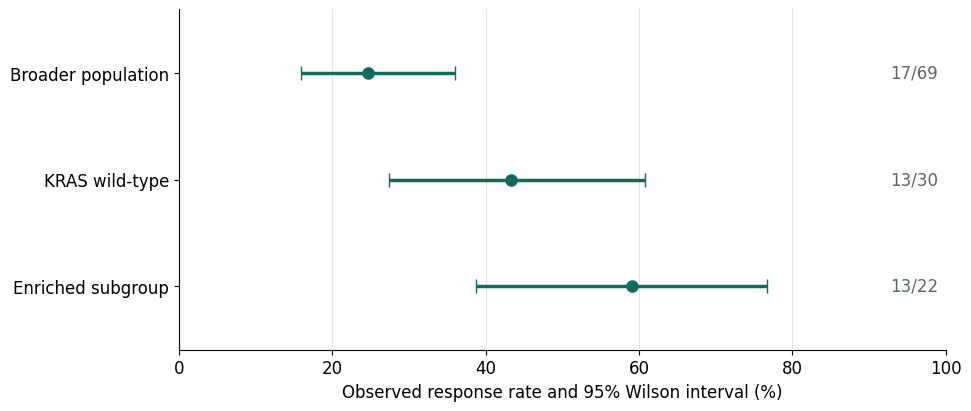

In [6]:
# Display inline in Jupyter. The authoring script optionally exports the same SVG.
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12,
                     'axes.spines.top': False, 'axes.spines.right': False})
chosen = [populations[i] for i in (0, 1, 4)]
fig, ax = plt.subplots(figsize=(9.6, 4), layout='constrained')
for y, (label, responses, patients) in enumerate(chosen):
    lo, hi = wilson(responses, patients)
    rate = responses / patients
    ax.errorbar(rate*100, y, xerr=[[(rate-lo)*100], [(hi-rate)*100]],
                fmt='o', color='#0e6b5e', capsize=5, markersize=8, linewidth=2.5)
    ax.text(99, y, f'{responses}/{patients}', ha='right', va='center', color='#5c665f')
ax.set_yticks(range(3), [row[0] for row in chosen])
ax.set_ylim(2.6, -0.6)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel('Observed response rate and 95% Wilson interval (%)')
ax.grid(axis='x', color='#d8dcd4', alpha=0.7)
ax.set_axisbelow(True)
if os.environ.get('IOVANCE_FIGURE_DIR'):
    fig.savefig(Path(os.environ['IOVANCE_FIGURE_DIR']) / 'wilson-intervals.svg')
plt.show()

## 5. Predict only after choosing assumptions

Use **50 new patients as an illustration**, not a claimed trial size.
With fixed p, $X_{future} \sim Binomial(m,p)$ and $E[X]=mp$.
Plugging in 13/22 treats p as known. The central 95% count interval uses the 0.025 and 0.975
quantiles of the count distribution. It is not a Wilson confidence interval.
Discrete count intervals may contain more than 95% probability.

The functions below evaluate the probability mass functions directly. The beta-binomial formula is
$P(X=k)=\binom{m}{k} B(k+a,m-k+b)/B(a,b)$, evaluated using log-gamma to avoid large intermediates.

In [7]:
def binomial_pmf(m, p):
    return [comb(m, k) * p**k * (1-p)**(m-k) for k in range(m+1)]

def log_beta(a, b):
    return lgamma(a) + lgamma(b) - lgamma(a+b)

def beta_binomial_pmf(m, a, b):
    return [exp(lgamma(m+1)-lgamma(k+1)-lgamma(m-k+1)
                + log_beta(k+a, m-k+b)-log_beta(a,b)) for k in range(m+1)]

def quantile(pmf, q):
    cumulative = 0.0
    for k, probability in enumerate(pmf):
        cumulative += probability
        if cumulative >= q:
            return k
    return len(pmf)-1  # rounding at the upper endpoint

def summarize(pmf):
    expected = sum(k*prob for k, prob in enumerate(pmf))
    lo, hi = quantile(pmf, 0.025), quantile(pmf, 0.975)
    coverage = sum(pmf[lo:hi+1])
    return expected, lo, hi, coverage

future_n = 50

In [8]:
for label, p in [('Wilson lower scenario', lower), ('Observed-rate scenario', p_hat),
                 ('Wilson upper scenario', upper)]:
    expected, lo, hi, coverage = summarize(binomial_pmf(future_n, p))
    print(f'{label:24s} p={p:.6f}  E[X]={expected:.1f}  interval={lo}-{hi}  mass={coverage:.3%}')
print('Separate fixed-p scenarios; their combined endpoints are not a calibrated prediction interval.')

Wilson lower scenario    p=0.387348  E[X]=19.4  interval=13-26  mass=95.901%
Observed-rate scenario   p=0.590909  E[X]=29.5  interval=23-36  mass=95.711%
Wilson upper scenario    p=0.767442  E[X]=38.4  interval=32-44  mass=97.189%
Separate fixed-p scenarios; their combined endpoints are not a calibrated prediction interval.


### A Bayesian alternative: beta-binomial

With a uniform Beta(1,1) prior and binomial likelihood for 13 responses and nine nonresponses,
$p\mid data \sim Beta(14,10)$. Integrating future binomial outcomes over this posterior produces
a beta-binomial predictive distribution. It includes parameter uncertainty **within the specified model**,
but does not automatically correct selection optimism or clinical population shifts.
Wilson does not provide this posterior; the prior and likelihood do.

Binomial, p=13/22             E[X]=29.5  interval=23-36  mass=95.711%
Beta-binomial, Beta(14,10)    E[X]=29.2  interval=17-40  mass=95.711%


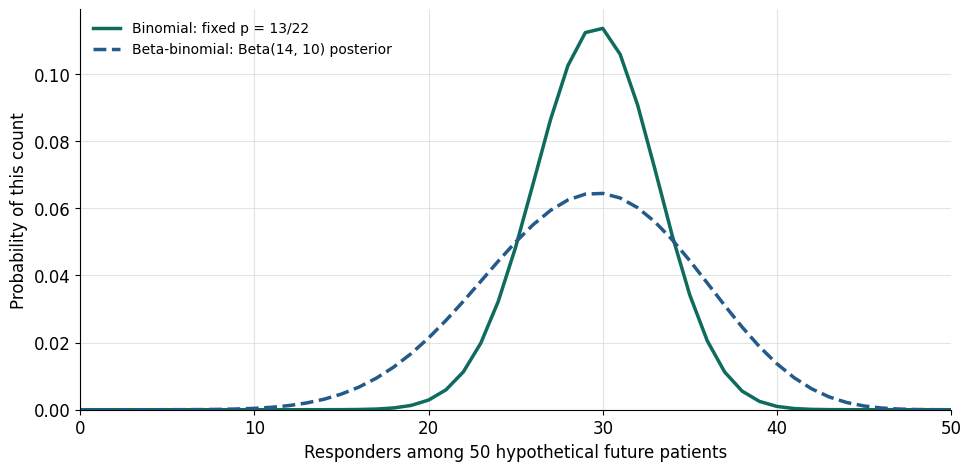

In [9]:
a, b = 1+x, 1+n-x
binomial = binomial_pmf(future_n, p_hat)
predictive = beta_binomial_pmf(future_n, a, b)
for label, pmf in [('Binomial, p=13/22', binomial), ('Beta-binomial, Beta(14,10)', predictive)]:
    expected, lo, hi, coverage = summarize(pmf)
    print(f'{label:29s} E[X]={expected:.1f}  interval={lo}-{hi}  mass={coverage:.3%}')

fig, ax = plt.subplots(figsize=(9.6, 4.6), layout='constrained')
counts = list(range(future_n+1))
ax.plot(counts, binomial, color='#0e6b5e', linewidth=2.5, label='Binomial: fixed p = 13/22')
ax.plot(counts, predictive, color='#245a8a', linestyle='--', linewidth=2.5,
        label='Beta-binomial: Beta(14, 10) posterior')
ax.set(xlabel='Responders among 50 hypothetical future patients',
       ylabel='Probability of this count', xlim=(0, future_n), ylim=(0, None))
ax.grid(color='#d8dcd4', alpha=0.7)
ax.legend(frameon=False, loc='upper left', fontsize=10)
if os.environ.get('IOVANCE_FIGURE_DIR'):
    fig.savefig(Path(os.environ['IOVANCE_FIGURE_DIR']) / 'predictive-counts.svg')
plt.show()

## 6. Check sensitivity rather than hiding assumptions

Priors below are illustrative choices, not priors calibrated to this therapy. Beta(1,1) and Beta(0.5,0.5)
are common weak priors; Beta(3,7) is an invented prior with mean 30% and prior strength a+b=10.
The 12/22 calculation changes the endpoint to confirmed responses at the cutoff; it does not predict
whether the pending response will ultimately be confirmed.
Neither prior sensitivity nor confirmed-response sensitivity corrects the retrospective search.

In [10]:
for name, prior_a, prior_b in [('Uniform', 1, 1), ('Jeffreys', 0.5, 0.5), ('Illustrative 30% prior', 3, 7)]:
    pa, pb = prior_a+x, prior_b+n-x
    expected, lo, hi, _ = summarize(beta_binomial_pmf(future_n, pa, pb))
    print(f'{name:24s} posterior Beta({pa:g},{pb:g})  E[X]={expected:.1f}  interval={lo}-{hi}')
confirmed_lo, confirmed_hi = wilson(12, 22)
print(f'Confirmed-only sensitivity: 12/22={12/22:.1%}; Wilson {confirmed_lo:.1%}-{confirmed_hi:.1%}')

Uniform                  posterior Beta(14,10)  E[X]=29.2  interval=17-40
Jeffreys                 posterior Beta(13.5,9.5)  E[X]=29.3  interval=17-41
Illustrative 30% prior   posterior Beta(16,16)  E[X]=25.0  interval=14-36
Confirmed-only sensitivity: 12/22=54.5%; Wilson 34.7%-73.1%


## 7. Validate prospectively

Fix subgroup criteria, outcome definition, analysis population, follow-up, and the analysis plan before
examining the new outcomes. Compare independently collected evidence with predictions recorded in advance.
Larger future samples reduce sampling uncertainty but do not by themselves repair selection bias.
Durability, safety, and trial design remain essential to interpretation. None of these response-count
calculations estimates the probability of regulatory approval or a stock-price outcome.

### Sources

- [Iovance release, 29 October 2026](https://ir.iovance.com/news-releases/news-release-details/iovance-reports-updated-iov-lun-202-results-and-adds-precision): aggregate counts and clinical context.
- [NIST Wilson interval reference](https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm).
- [SciPy beta-binomial PMF reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html).

The final cell checks numerical identities and a known reference interval. It is not a validation of the clinical model.

In [11]:
assert isclose(p_hat, 13/22)
assert isclose(lower, 0.387348184763, abs_tol=1e-10)
assert isclose(upper, 0.767441838035, abs_tol=1e-10)
assert isclose(sum(binomial), 1, abs_tol=1e-12)
assert isclose(sum(predictive), 1, abs_tol=1e-12)
assert isclose(sum(k*prob for k, prob in enumerate(predictive)), future_n*a/(a+b), abs_tol=1e-10)
assert summarize(binomial)[1:3] == (23, 36)
assert summarize(predictive)[1:3] == (17, 40)
assert mean(selected_rates) > mean(fixed_rates)
print('Numerical checks passed. Model assumptions still require scientific validation.')

Numerical checks passed. Model assumptions still require scientific validation.
